# SALAD architecture walkthrough
Two models, drawn with `torchview` and then stepped through by hand:

| | what it does | tensor in → out |
|---|---|---|
| **A. VAE** (`models/vae`) | compresses a motion clip into a small skeleto-temporal latent | `[B, T, 251]` → `[B, T/4, 7, 32]` → `[B, T, 251]` |
| **B. Denoiser** (`models/denoiser`) | diffusion model that denoises that latent, conditioned on text + timestep | `[B, T/4, 7, 32]` → `[B, T/4, 7, 32]` |

Generation = text → *denoiser* (50 DDIM steps from noise) → latent → *VAE decoder* → motion.

In [1]:
import os, sys, zlib
from pathlib import Path
from argparse import Namespace

# run from the repo root so `utils` resolves to the top-level package (not visualization/utils)
if Path.cwd().name == "visualization":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, os.getcwd())

import numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt
from torchview import draw_graph

from utils.get_opt import get_opt
from utils.motion_process import recover_from_ric
from utils.paramUtil import kit_kinematic_chain as CHAIN

torch.manual_seed(0)
DEVICE = "cpu"                       # everything here is small enough for CPU

VAE_NAME = "vae_kit_v1"              # checkpoints/kit/<VAE_NAME>; random init if it does not exist
DENOISER_NAME = None                 # e.g. "denoiser_kit_v1" once trained; None -> random init
USE_REAL_CLIP = False                # True downloads openai/clip-vit-base-patch32 (~600 MB) on first use
SAVE_DIR = None                      # e.g. "visualization/renders/arch" to also write every graph as .svg

In [2]:
def show_graph(model, inputs, depth=1, name="graph", expand_nested=True, **kw):
    # torchview diagram. `inputs` is a tensor or a tuple of positional args. Raise `depth` to open up more sub-modules.
    # torchview 0.2.7 raises KeyError at depths where a ResSTConv's inner Sequential (which starts with the
    # Identity "norm") would be a leaf box, e.g. depth=3 on vae.conv_enc; go one level up or down.
    g = draw_graph(model, input_data=inputs, depth=depth, graph_name=name, device=DEVICE,
                   expand_nested=expand_nested, **kw).visual_graph
    if SAVE_DIR:
        os.makedirs(SAVE_DIR, exist_ok=True)
        g.render(os.path.join(SAVE_DIR, name), format="svg", cleanup=True)
    return g


def shape_table(model, *inputs, depth=1, skip=()):
    # Run one forward pass and print output shape + parameter count of every sub-module up to `depth` name levels.
    # `skip`: name fragments to leave out (rows appear in call order, children before their parent).
    rows, hooks = [], []
    def first_tensor(o):
        return o if torch.is_tensor(o) else first_tensor(o[0])
    for mname, m in model.named_modules():
        if mname and mname.count(".") < depth and not any(k in mname for k in skip):
            hooks.append(m.register_forward_hook(
                lambda m, i, o, mname=mname: rows.append(
                    (mname, type(m).__name__, tuple(first_tensor(o).shape), sum(p.numel() for p in m.parameters())))))
    with torch.no_grad():
        model(*inputs)
    for h in hooks:
        h.remove()
    w = max(len(r[0]) for r in rows)
    print(f"{'module':<{w}}  {'type':<20} {'output shape':<22} {'params':>10}")
    for n, t, s, p in rows:
        print(f"{n:<{w}}  {t:<20} {str(list(s)):<22} {p:>10,}")
    print(f"{'total':<{w}}  {'':<20} {'':<22} {sum(p.numel() for p in model.parameters()):>10,}")

## 0. One real clip to push through the models
`[T, 251]` KIT-ML features, z-normalised exactly like `MotionDataset`. Falls back to random numbers if the dataset is not on disk.

In [3]:
J, T = 21, 64                                   # KIT joints, VAE training window
ROOT = Path("dataset/KIT-ML")
meta = Path(f"checkpoints/kit/{VAE_NAME}/meta")

if ROOT.exists():
    mean = np.load(meta / "mean.npy" if meta.exists() else ROOT / "Mean.npy")
    std = np.load(meta / "std.npy" if meta.exists() else ROOT / "Std.npy")
    for cid in (l.strip() for l in open(ROOT / "test.txt")):
        f = ROOT / "new_joint_vecs" / f"{cid}.npy"
        if f.exists() and len(np.load(f)) >= T:
            break
    raw = np.load(f)[:T]
    caption = open(ROOT / "texts" / f"{cid}.txt").readline().split("#")[0]
    motion = torch.from_numpy((raw - mean) / std).float()[None]          # [1, T, 251]
else:
    mean, std, caption = np.zeros(251), np.ones(251), "a person walks forward"
    motion = torch.randn(1, T, 251)

print("motion", tuple(motion.shape), "| caption:", caption)

motion (1, 64, 251) | caption: A human stretches and performs a squad.


---
# Part A — VAE
`models/vae/model.py`. Five pieces:

```
motion [B,T,251] ─ MotionEncoder ─▶ [B,T,21,32] ─ STConvEncoder ─▶ [B,T/4,7,32] ─ dist (MultiLinear) ─▶ mu, logvar ─ reparameterize ─▶ z
z [B,T/4,7,32]   ─ STConvDecoder ─▶ [B,T,21,32] ─ MotionDecoder ─▶ motion [B,T,251]
```

In [4]:
from models.vae.model import VAE

vae_opt_path = f"checkpoints/kit/{VAE_NAME}/opt.txt"
if os.path.exists(vae_opt_path):
    vae_opt = get_opt(vae_opt_path, DEVICE)
else:                                           # defaults of options/vae_option.py
    vae_opt = Namespace(dataset_name="kit", pose_dim=251, contact_joints=[19, 20, 14, 15], latent_dim=32,
                        kernel_size=3, n_layers=2, n_extra_layers=1, norm="none", activation="gelu", dropout=0.1)

vae = VAE(vae_opt).eval()
for fname in ("net_best_fid.tar", "net_best_val.tar", "latest.tar"):
    ckpt_path = f"checkpoints/kit/{VAE_NAME}/model/{fname}"
    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location="cpu")
        vae.load_state_dict(ckpt["vae"])
        print(f"loaded {ckpt_path} (epoch {ckpt.get('epoch')})")
        break
else:
    print("no VAE checkpoint found -> random weights (diagrams are identical, reconstructions will be noise)")

Reading checkpoints/kit/vae_kit_v1/opt.txt
loaded checkpoints/kit/vae_kit_v1/model/net_best_val.tar (epoch 12)


## A1. Diagrams
**Whole VAE, top level.** Each box is one sub-module of `VAE`; the loose ops in the middle are `chunk → exp/randn_like → mu + eps·std` (the reparameterisation trick).

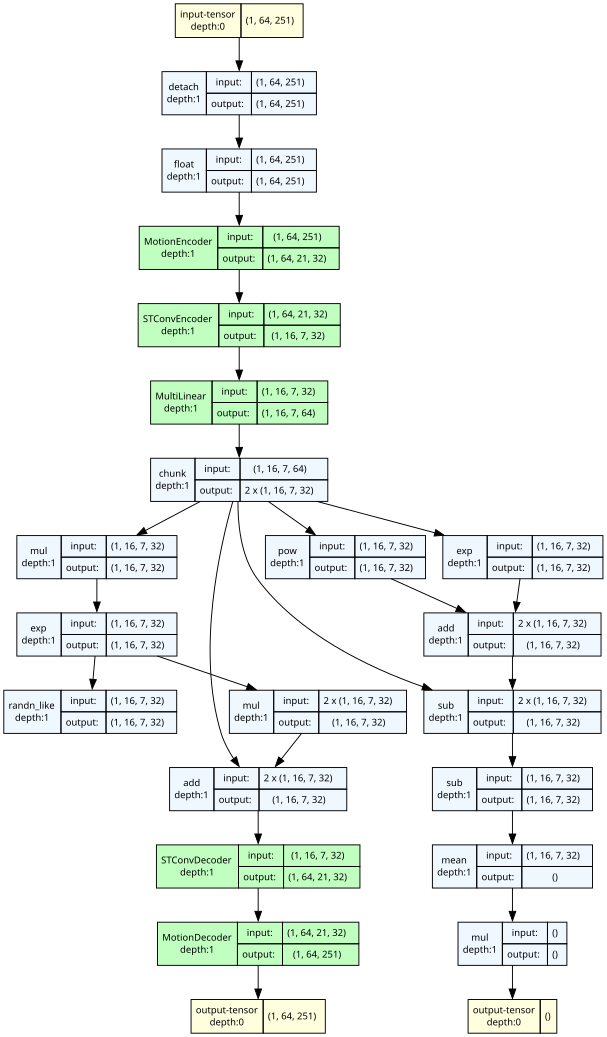

In [5]:
show_graph(vae, motion, depth=1, name="vae_depth1")

**Skeleto-temporal encoder, opened up.** Two stages, each `ResSTConv × (n_extra_layers + 1)` then `STPool`. Every `STPool` halves time and coarsens the skeleton: 21 → 12 → 7 joints.

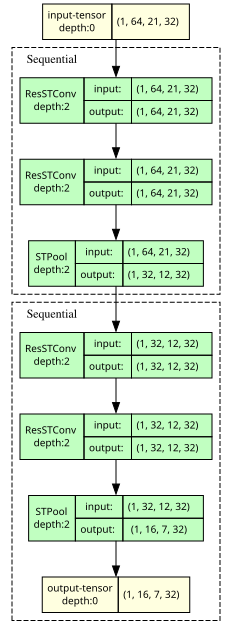

In [6]:
h_joint = torch.randn(1, T, J, vae_opt.latent_dim)          # what MotionEncoder hands to the conv encoder
show_graph(vae.conv_enc, h_joint, depth=2, name="vae_conv_enc")

**One `ResSTConv` block.** `x + [act → STConv → act → STConv → dropout](x)`. Inside each `STConv` there are two parallel branches that are summed: a graph conv over joints (`linear1`, `linear2` + adjacency matmul) and a `Conv1d` over time.

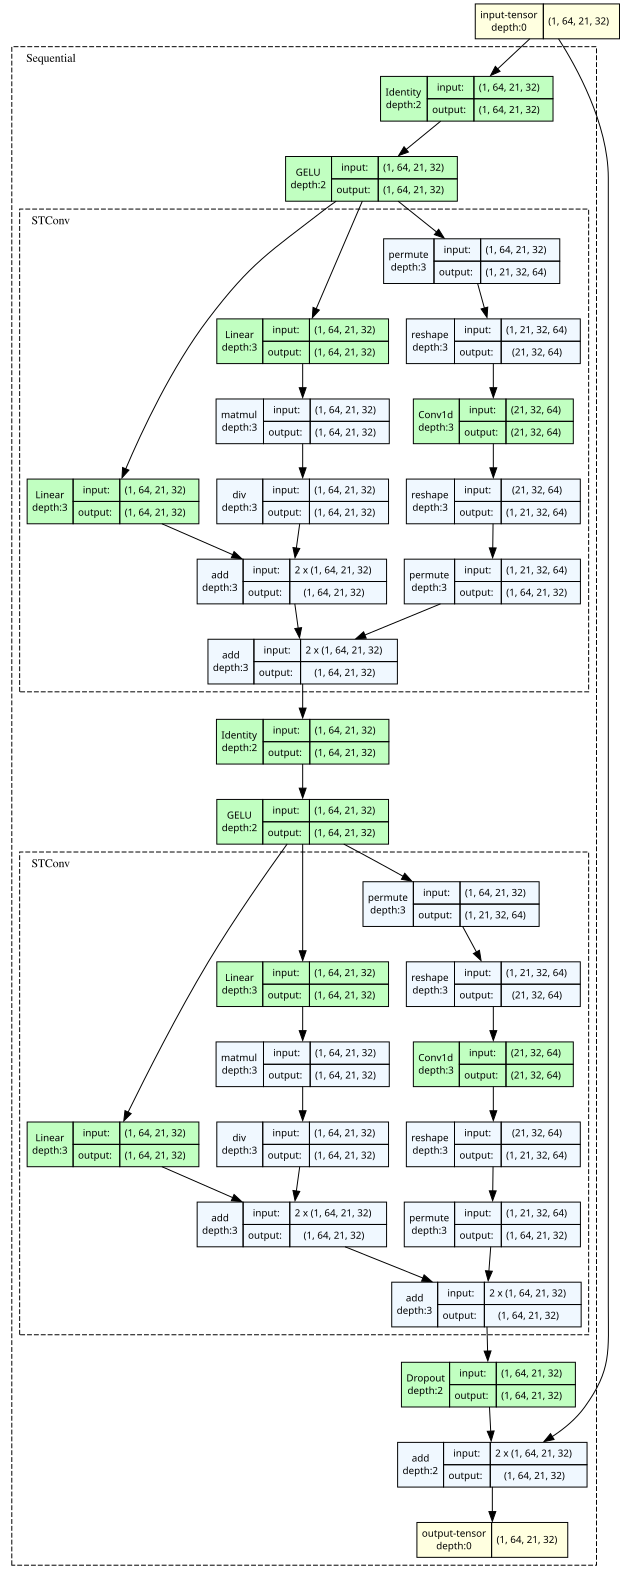

In [7]:
show_graph(vae.conv_enc.layers[0][0], h_joint, depth=4, name="vae_resstconv")

**Decoder side** — mirror image: `STUnpool` (7 → 12 → 21 joints, time ×2) followed by `ResSTConv`s.

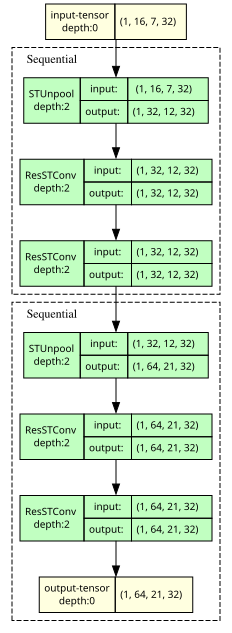

In [8]:
z_dummy = torch.randn(1, T // 4, 7, vae_opt.latent_dim)
show_graph(vae.conv_dec, z_dummy, depth=2, name="vae_conv_dec")

**Shapes and parameter counts** for the same forward pass.

In [9]:
shape_table(vae, motion, depth=4, skip=("motion_enc.layers", "motion_dec.layers"))      # 21 identical per-joint MLPs hidden

module               type                 output shape               params
motion_enc           MotionEncoder        [1, 64, 21, 32]            30,880
conv_enc.layers.0.0  ResSTConv            [1, 64, 21, 32]            11,314
conv_enc.layers.0.1  ResSTConv            [1, 64, 21, 32]            11,314
conv_enc.layers.0.2  STPool               [1, 32, 12, 32]               252
conv_enc.layers.0    Sequential           [1, 32, 12, 32]            22,880
conv_enc.layers.1.0  ResSTConv            [1, 32, 12, 32]            10,720
conv_enc.layers.1.1  ResSTConv            [1, 32, 12, 32]            10,720
conv_enc.layers.1.2  STPool               [1, 16, 7, 32]                 84
conv_enc.layers.1    Sequential           [1, 16, 7, 32]             21,524
conv_enc             STConvEncoder        [1, 16, 7, 32]             44,404
dist                 MultiLinear          [1, 16, 7, 64]             14,784
conv_dec.layers.0.0  STUnpool             [1, 32, 12, 32]                84
conv_dec.lay

## A2. The process, step by step
### Step 1 — `MotionEncoder`: 251 flat features → one 32-d token per joint
The 251 numbers are regrouped by joint, and **each joint has its own small MLP** (`Linear → GELU → Linear`):

- root (joint 0): 4 root features (rot-vel, xz-vel, height) + 3 velocity = **7**
- every other joint: 3 position + 6 rotation + 3 velocity = **12**
- the 4 foot joints additionally get their contact bit = **13**

In [ ]:
enc = vae.motion_enc
in_dims = [layer[0].in_features for layer in enc.layers]
print("per-joint input dims:", in_dims, "-> sum", sum(in_dims))

with torch.no_grad():
    h0 = enc(motion)
print("MotionEncoder:", tuple(motion.shape), "->", tuple(h0.shape), " [B, T, J, D]")

fig, ax = plt.subplots(figsize=(8, 2.2))
ax.bar(range(J), in_dims, color=["C3" if d == 7 else "C1" if d == 13 else "C0" for d in in_dims])
ax.set(xlabel="joint index", ylabel="input dims", xticks=range(J), title="features per joint (red = root, orange = foot contact joints)")
plt.show()

### Step 2 — `STConv`: mix information along bones and along time
For a tensor `x: [B, T, J, D]`:

- **graph conv** (over joints): `linear1(x) + A·linear2(x) / deg` — each joint gets its own features plus the mean of its skeleton neighbours (`A` = adjacency with self-loops)
- **temporal conv** (over frames): a `Conv1d(kernel=3)` run independently for every joint (joints are folded into the batch: `[B·J, D, T]`)
- output = sum of the two

The cell below recomputes one `STConv` by hand and checks it against the module.

In [ ]:
stconv = vae.conv_enc.layers[0][0].layers[2]          # first STConv of the first ResSTConv
A = stconv.adj_matrix
B_, T_, J_, D_ = h0.shape

with torch.no_grad():
    gc = stconv.graph_conv
    graph_out = gc.linear1(h0) + (A @ gc.linear2(h0)) / (A.sum(-1, keepdim=True) + 1e-6)     # over joints

    temp_in = h0.permute(0, 2, 3, 1).reshape(B_ * J_, D_, T_)                               # [B*J, D, T]
    temp_out = stconv.temp_conv(temp_in).reshape(B_, J_, D_, T_).permute(0, 3, 1, 2)        # over time

    manual = graph_out + temp_out
    print("matches STConv.forward:", torch.allclose(manual, stconv(h0), atol=1e-5))

# the adjacency matrix used at each of the three skeleton resolutions
adjs = [vae.conv_enc.layers[0][0].layers[2].adj_matrix,      # 21 joints
        vae.conv_enc.layers[1][0].layers[2].adj_matrix,      # 12 joints
        vae.conv_dec.layers[0][1].layers[2].adj_matrix]      # 12 joints again on the way back up
fig, axes = plt.subplots(1, 2, figsize=(7, 3.3))
for ax, a, t in zip(axes, adjs, ["stage 1: 21 joints", "stage 2: 12 joints"]):
    ax.imshow(a, cmap="Blues"); ax.set_title(f"adjacency, {t}"); ax.set(xlabel="joint", ylabel="joint")
plt.tight_layout(); plt.show()

### Step 3 — `STPool`: shrink the skeleton and halve the frame rate
`STPool` is parameter-free: a fixed averaging matrix `[J_out, J_in]` merges groups of neighbouring joints (groups overlap), then `AvgPool1d(2)` over time.

`21 joints → 12 body parts → 7 parts` (root, two legs, spine, two arms, head) and `T → T/2 → T/4`.

In [ ]:
pools = [stage[-1] for stage in vae.conv_enc.layers]                   # the STPool at the end of each stage
PART_NAMES = ["root", "L-lower", "R-lower", "spine", "L-upper", "R-upper", "head"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3), gridspec_kw={"width_ratios": [21, 12]})
for ax, p in zip(axes, pools):
    W = p.skeleton_pool
    ax.imshow(W, cmap="viridis"); ax.set(xlabel="input joint", ylabel="output joint", title=f"pool weights {tuple(W.shape)}")
axes[1].set_yticks(range(7)); axes[1].set_yticklabels(PART_NAMES)
plt.tight_layout(); plt.show()

# the same thing drawn on the body: pooled joint = average position of the joints it merges
xyz = recover_from_ric(motion[0] * torch.from_numpy(std).float() + torch.from_numpy(mean).float(), J)[0]   # frame 0, [21, 3]
levels = [(xyz, vae.conv_enc.edge_list[0])]
for p, edges in zip(pools, vae.conv_enc.edge_list[1:]):
    levels.append((p.skeleton_pool @ levels[-1][0], edges))

fig, axes = plt.subplots(1, 3, figsize=(9, 4), sharex=True, sharey=True)
for ax, (pos, edges) in zip(axes, levels):
    for i, j in edges:
        ax.plot(pos[[i, j], 0], pos[[i, j], 1], "k-", lw=1)
    ax.scatter(pos[:, 0], pos[:, 1], c="C3", zorder=3)
    for k, (x, y, _) in enumerate(pos.tolist()):
        ax.annotate(str(k), (x, y), textcoords="offset points", xytext=(4, 2), fontsize=7)
    ax.set_title(f"{len(pos)} nodes"); ax.set_aspect("equal"); ax.axis("off")
plt.suptitle("skeleton graph at each encoder level (front view, frame 0)"); plt.show()

# shapes through the two encoder stages
with torch.no_grad():
    h = h0
    print("in       ", tuple(h.shape))
    for i, stage in enumerate(vae.conv_enc.layers):
        h = stage(h)
        print(f"stage {i}  ", tuple(h.shape))
h_enc = h

### Step 4 — latent distribution and sampling
`dist` is a `MultiLinear`: **7 separate linear layers, one per body part** (`32 → 64`). The 64 outputs are split into `mu` and `logvar`, and

`z = mu + eps · exp(0.5·logvar)`,  `KL = 0.5 · mean(mu² + exp(logvar) − logvar − 1)`

`z` (`[B, T/4, 7, 32]`) is what the diffusion model is trained on.

In [ ]:
with torch.no_grad():
    mu, logvar = vae.dist(h_enc).chunk(2, dim=-1)
    z = vae.reparameterize(mu, logvar)
    kl = 0.5 * torch.mean(mu ** 2 + logvar.exp() - logvar - 1.0)

print("dist weight", tuple(vae.dist.weight.shape), "= [parts, in, out]")
print("mu / logvar / z:", tuple(mu.shape), "| KL =", round(kl.item(), 4), "| mean std =", round((0.5 * logvar).exp().mean().item(), 3))
print(f"compression: {motion[0].numel()} numbers -> {z[0].numel()} ({motion[0].numel() / z[0].numel():.1f}x)")

fig, axes = plt.subplots(1, 7, figsize=(13, 2.6), sharey=True)
for k, ax in enumerate(axes):
    im = ax.imshow(z[0, :, k].T, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
    ax.set_title(PART_NAMES[k], fontsize=9); ax.set_xlabel("latent frame")
axes[0].set_ylabel("channel")
fig.colorbar(im, ax=axes, fraction=0.015); plt.suptitle("latent z, one panel per body part", y=1.05); plt.show()

### Step 5 — decode
`STUnpool` copies each coarse part back to every joint it was pooled from (sum over the overlapping groups) and linearly upsamples time ×2; `ResSTConv`s refine; `MotionDecoder` runs one MLP per joint and re-packs the 251-d vector.

In [ ]:
with torch.no_grad():
    h = z
    print("z        ", tuple(h.shape))
    for i, stage in enumerate(vae.conv_dec.layers):
        h = stage(h)
        print(f"stage {i}  ", tuple(h.shape))
    recon = vae.motion_dec(h)
    print("motion   ", tuple(recon.shape))

fig, axes = plt.subplots(1, 2, figsize=(7, 3), gridspec_kw={"width_ratios": [7, 12]})
for ax, stage in zip(axes, vae.conv_dec.layers):
    W = stage[0].skeleton_unpool
    ax.imshow(W, cmap="viridis"); ax.set(xlabel="input node", ylabel="output node", title=f"unpool weights {tuple(W.shape)}")
plt.tight_layout(); plt.show()

**Reconstruction check** — input vs. decoded, in feature space and as skeletons (only meaningful with a trained checkpoint).

In [ ]:
print("normalised L1 error:", round((recon - motion).abs().mean().item(), 4))

feat_names = {0: "root rot vel", 3: "root height", 4: "joint 1 pos x", 250: "foot contact"}
fig, axes = plt.subplots(1, 4, figsize=(14, 2.4))
for ax, (idx, name) in zip(axes, feat_names.items()):
    ax.plot(motion[0, :, idx], label="input"); ax.plot(recon[0, :, idx], "--", label="recon")
    ax.set(title=f"feature {idx}: {name}", xlabel="frame")
axes[0].legend(); plt.tight_layout(); plt.show()

denorm = lambda m: m[0] * torch.from_numpy(std).float() + torch.from_numpy(mean).float()
gt_xyz, rec_xyz = recover_from_ric(denorm(motion), J), recover_from_ric(denorm(recon), J)
frames = [0, T // 4, T // 2, 3 * T // 4, T - 1]
fig, axes = plt.subplots(1, len(frames), figsize=(13, 3.2))
for ax, fr in zip(axes, frames):
    for pos, c, lab in [(gt_xyz[fr], "0.6", "input"), (rec_xyz[fr], "C3", "recon")]:
        for n, chain in enumerate(CHAIN):
            ax.plot(pos[chain, 0], pos[chain, 1], color=c, lw=2, label=lab if n == 0 else None)
    ax.set_title(f"frame {fr}"); ax.set_aspect("equal"); ax.axis("off")
axes[0].legend(fontsize=7); plt.show()

---
# Part B — Denoiser
`models/denoiser/model.py`. A transformer that sees the noisy latent as a **grid of tokens `[T/4 frames × 7 parts]`** and predicts the denoising target for every token.

```
noisy latent [B,T',7,32] ─ InputProcess (MLP) ─▶ [B,T',7,256] ─ + positional emb ─┐
timestep t ─ TimestepEmbedding ─▶ [B,256] ───────── FiLM in every layer ───────────┤
text ─ frozen CLIP ─▶ [B,77,512] ─ word_emb (Linear) ─▶ [B,77,256] ─ cross-attn ───┤
                                                                                   ▼
                                                       SkipTransformer (5 STTransformerLayers)
                                                                                   ▼
                                                       OutputProcess (MLP) ─▶ [B,T',7,32]
```

In [ ]:
import models.denoiser.model as denoiser_module
from models.denoiser.model import Denoiser
from models.denoiser.transformer import featurewise_affine
from diffusers import DDIMScheduler


class StubCLIP(nn.Module):
    # Stand-in for FrozenCLIPTextEncoder: same output shapes, random (but per-text deterministic) values, no download.
    def __init__(self, opt):
        super().__init__()

    def encode_text(self, text):
        emb, n_tok = [], []
        for t in text:
            g = torch.Generator().manual_seed(zlib.crc32(t.encode()))
            emb.append(torch.randn(77, 512, generator=g))
            n_tok.append(min(len(t.split()) + 2, 77))            # words + <start> + <end>
        n_tok = torch.tensor(n_tok)
        mask = torch.arange(77)[None] < n_tok[:, None]           # True = real token
        return torch.stack(emb), mask, n_tok - 1


if not USE_REAL_CLIP:
    denoiser_module.FrozenCLIPTextEncoder = StubCLIP

# defaults of options/denoiser_option.py
den_opt = Namespace(latent_dim=256, n_heads=8, n_layers=5, ff_dim=1024, activation="gelu", dropout=0.1,
                    clip_version="ViT-B/32", checkpoints_dir="./checkpoints", device=DEVICE,
                    cond_scale=7.5, num_train_timesteps=1000, num_inference_timesteps=50,
                    beta_start=0.00085, beta_end=0.012, beta_schedule="scaled_linear", prediction_type="v_prediction")

denoiser = Denoiser(den_opt, vae_opt.latent_dim).eval()
if DENOISER_NAME:
    ckpt = torch.load(f"checkpoints/kit/{DENOISER_NAME}/model/net_best_fid.tar", map_location="cpu")
    print(denoiser.load_state_dict(ckpt["denoiser"], strict=False))       # CLIP weights are not in the checkpoint
else:
    print("denoiser has random weights -> structure and shapes are real, attention maps / samples are not meaningful")

scheduler = DDIMScheduler(num_train_timesteps=den_opt.num_train_timesteps, beta_start=den_opt.beta_start,
                          beta_end=den_opt.beta_end, beta_schedule=den_opt.beta_schedule,
                          prediction_type=den_opt.prediction_type, clip_sample=False)

print("trainable params (without CLIP):", f"{sum(p.numel() for p in denoiser.parameters_without_clip()):,}")

## B1. Diagrams
`Denoiser.forward` takes a list of strings, which torchview cannot trace. `DenoiserView` below is the same forward pass with the CLIP output passed in as a tensor, so the text branch shows up as a third input.

In [ ]:
class DenoiserView(nn.Module):
    # Denoiser.forward with the text already CLIP-encoded: (noisy_latent, timestep, clip_word_emb) -> prediction.
    def __init__(self, denoiser, ca_mask):
        super().__init__()
        self.d, self.ca_mask = denoiser, ca_mask

    def forward(self, x, timestep, clip_word_emb):
        d = self.d
        x = d.input_process(x)                                          # [B, T, J, 256]
        B, T, J, D = x.shape
        t_emb = d.timestep_emb(timestep).expand(B, D)                   # [B, 256]
        word_emb = d.word_emb(clip_word_emb)                            # [B, 77, 256]
        x = d.pos_emb(x.reshape(B, T * J, D)).reshape(B, T, J, D)
        x, _ = d.transformer(x, t_emb, word_emb, ca_mask=~self.ca_mask)
        return d.output_process(x)                                      # [B, T, J, 32]


with torch.no_grad():
    clip_emb, ca_mask, _ = denoiser.clip_model.encode_text([caption])   # [1, 77, 512], [1, 77]
clip_emb, ca_mask = clip_emb.to(DEVICE), ca_mask.to(DEVICE)

t = torch.tensor([500])
noise = torch.randn_like(z)
z_t = scheduler.add_noise(z, noise, t)                                  # the denoiser's input during training

view = DenoiserView(denoiser, ca_mask).eval()
with torch.no_grad():
    same = torch.allclose(view(z_t, t, clip_emb), denoiser(z_t, t, [caption])[0], atol=1e-5)
print("DenoiserView == Denoiser.forward:", same)
print("z_t", tuple(z_t.shape), "| t", t.tolist(), "| clip", tuple(clip_emb.shape), "| real tokens:", int(ca_mask.sum()))

**Whole denoiser, top level.** Three inputs, one output with the same shape as the noisy latent.

In [ ]:
show_graph(view, (z_t, t, clip_emb), depth=2, name="denoiser_depth2")

**`SkipTransformer`.** U-Net-style: 2 input blocks → middle block → 2 output blocks. Before each output block the saved activation of the matching input block is concatenated and squeezed back to 256-d by a `Linear(512, 256)`.

In [ ]:
with torch.no_grad():
    tok = denoiser.input_process(z_t)                                   # [1, T', 7, 256]
    t_emb = denoiser.timestep_emb(t).expand(1, -1)                      # [1, 256]
    word = denoiser.word_emb(clip_emb)                                  # [1, 77, 256]

class TransformerView(nn.Module):
    def __init__(self, tr, ca_mask):
        super().__init__(); self.tr, self.ca_mask = tr, ca_mask
    def forward(self, x, t_emb, word_emb):
        return self.tr(x, t_emb, word_emb, ca_mask=~self.ca_mask)[0]

show_graph(TransformerView(denoiser.transformer, ca_mask).eval(), (tok, t_emb, word), depth=2, name="denoiser_skip_transformer")

**One `STTransformerLayer`.** Four residual sub-blocks in this order — temporal attention, skeletal attention, cross-attention to text, feed-forward — each one modulated by its own `DenseFiLM(timestep)` before being added back.

The code calls `attn.forward(...)` directly, so the attention modules have no box of their own here (or in the shape table below): each shows up as its `Wq/Wk/Wv` Linears → `matmul` → `softmax` → `Wo`.

In [ ]:
class LayerView(nn.Module):
    def __init__(self, layer, ca_mask):
        super().__init__(); self.layer, self.ca_mask = layer, ca_mask
    def forward(self, x, word_emb, t_emb):
        return self.layer(x, word_emb, t_emb, memory_mask=~self.ca_mask)[0]

block = denoiser.transformer.input_blocks[0]
show_graph(LayerView(block, ca_mask).eval(), (tok, word, t_emb), depth=2, name="denoiser_st_layer")

**Shapes and parameter counts.**

In [ ]:
shape_table(view, z_t, t, clip_emb, depth=4, skip=(".layers", ".mlp", ".dropout", "middle_block."))
print("\ninside one STTransformerLayer:")
shape_table(LayerView(block, ca_mask).eval(), tok, word, t_emb, depth=2)

## B2. The process, step by step
### Step 1 — the three inputs become 256-d
- **latent tokens**: `InputProcess` MLP `32 → 256`, then a sinusoidal positional embedding over the flattened `T'·7` sequence
- **timestep**: sinusoidal features (256 freqs) → MLP → one 256-d vector per sample
- **text**: frozen CLIP gives 77 token embeddings (512-d); a trainable `Linear` maps them to 256-d. A mask marks which of the 77 are padding.

In [ ]:
with torch.no_grad():
    Bn, Tn, Jn, Dn = tok.shape
    x0 = denoiser.pos_emb(tok.reshape(Bn, Tn * Jn, Dn)).reshape(Bn, Tn, Jn, Dn)
    ts = torch.arange(0, 1000, 10)
    freq = denoiser.timestep_emb.timestep_embedding(ts, 256)            # before the MLP

print("latent tokens:", tuple(z_t.shape), "->", tuple(x0.shape))
print("timestep     :", tuple(t.shape), "->", tuple(t_emb.shape))
print("text         :", f"'{caption}'", "->", tuple(clip_emb.shape), "->", tuple(word.shape))

fig, axes = plt.subplots(1, 2, figsize=(12, 2.8))
axes[0].imshow(freq.T, aspect="auto", cmap="RdBu_r", extent=[0, 1000, 256, 0])
axes[0].set(title="sinusoidal timestep features", xlabel="diffusion timestep t", ylabel="feature")
axes[1].imshow(denoiser.pos_emb.pe[0, :Tn * Jn].T, aspect="auto", cmap="RdBu_r")
axes[1].set(title=f"positional embedding for the {Tn}x{Jn} = {Tn * Jn} tokens", xlabel="token index (frame*7 + part)", ylabel="feature")
plt.tight_layout(); plt.show()

### Step 2 — one `STTransformerLayer` by hand
The same `[B, T', 7, 256]` tensor is **reshaped three different ways** so that plain attention acts along a different axis each time:

| sub-block | reshape | attends over |
|---|---|---|
| temporal attention | `[B·7, T', D]` | frames, separately for each body part |
| skeletal attention | `[B·T', 7, D]` | body parts, separately for each frame |
| cross attention | `[B, T'·7, D]` × text `[B, 77, D]` | every motion token looks at the words |
| feed-forward | `[B, T', 7, D]` | per token |

Each result goes through FiLM, `out · (scale + 1) + shift`, where `(scale, shift)` come from the timestep embedding, and is then added to `x`.

In [ ]:
with torch.no_grad():
    B_, T_, J_, D_ = x0.shape
    film = {k: getattr(block, f"{k}_film")(t_emb) for k in ("temp", "skel", "cross", "ffn")}    # each: (scale, shift) [B,1,1,D]

    # temporal attention: joints folded into the batch
    ta, ta_w = block._ta_block(x0.transpose(1, 2).reshape(B_ * J_, T_, D_))
    x1 = x0 + featurewise_affine(ta.reshape(B_, J_, T_, D_).transpose(1, 2), film["temp"])

    # skeletal attention: frames folded into the batch
    sa, sa_w = block._sa_block(x1.reshape(B_ * T_, J_, D_))
    x2 = x1 + featurewise_affine(sa.reshape(B_, T_, J_, D_), film["skel"])

    # cross attention: all T'*7 tokens query the text tokens (padding masked out)
    ca, ca_w = block._ca_block(x2.reshape(B_, T_ * J_, D_), word, mask=~ca_mask)
    x3 = x2 + featurewise_affine(ca.reshape(B_, T_, J_, D_), film["cross"])

    # feed-forward
    x4 = x3 + featurewise_affine(block._ff_block(x3), film["ffn"])

    ref, _ = block(x0, word, t_emb, memory_mask=~ca_mask)

print("matches STTransformerLayer.forward:", torch.allclose(x4, ref, atol=1e-5))
print("temporal attn weights", tuple(ta_w.shape), " [B*J, heads, T', T']")
print("skeletal attn weights", tuple(sa_w.shape), " [B*T', heads, J, J]")
print("cross    attn weights", tuple(ca_w.shape), " [B, heads, T'*J, 77]")

In [ ]:
n_tok = int(ca_mask.sum())
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))

im = axes[0].imshow(ta_w.mean(1)[0], cmap="magma")
axes[0].set(title=f"temporal attention ({PART_NAMES[0]})", xlabel="key frame", ylabel="query frame"); fig.colorbar(im, ax=axes[0])

im = axes[1].imshow(sa_w.mean(1)[0], cmap="magma")
axes[1].set(title="skeletal attention (frame 0)", xticks=range(7), yticks=range(7))
axes[1].set_xticklabels(PART_NAMES, rotation=45, ha="right"); axes[1].set_yticklabels(PART_NAMES); fig.colorbar(im, ax=axes[1])

im = axes[2].imshow(ca_w.mean(1)[0].reshape(T_, J_, -1).mean(0)[:, :n_tok], cmap="magma", aspect="auto")
axes[2].set(title="cross attention (mean over frames)", xlabel="text token", yticks=range(7)); axes[2].set_yticklabels(PART_NAMES); fig.colorbar(im, ax=axes[2])
plt.suptitle("attention maps of the first layer, averaged over heads" + ("" if DENOISER_NAME else "  (random weights)"))
plt.tight_layout(); plt.show()

### Step 3 — through the whole `SkipTransformer`
Follow the token tensor across the five layers; `need_attn=True` returns the attention maps of every layer stacked on dim 1 (this is what `visualize_attn.ipynb` and the editing code consume).

In [ ]:
with torch.no_grad():
    out_tok, (sa_all, ta_all, ca_all) = denoiser.transformer(x0, t_emb, word, ca_mask=~ca_mask, need_attn=True)
    pred = denoiser.output_process(out_tok)

print("transformer out", tuple(out_tok.shape), "-> OutputProcess ->", tuple(pred.shape))
print("skeletal attn  ", tuple(sa_all.shape), " [B*T', layers, heads, J, J]")
print("temporal attn  ", tuple(ta_all.shape), " [B*J, layers, heads, T', T']")
print("cross attn     ", tuple(ca_all.shape), " [B, layers, heads, T'*J, 77]")

## B3. The diffusion process around the denoiser
### Forward (training): noise a clean latent, ask the denoiser for the target
`z_t = √ᾱ_t · z_0 + √(1−ᾱ_t) · ε`. With `prediction_type="v_prediction"` the regression target is `v = √ᾱ_t · ε − √(1−ᾱ_t) · z_0`.

In [ ]:
abar = scheduler.alphas_cumprod
steps = [0, 250, 500, 750, 999]

fig, axes = plt.subplots(1, len(steps) + 1, figsize=(15, 2.6), gridspec_kw={"width_ratios": [1.6] + [1] * len(steps)})
axes[0].plot(abar.sqrt(), label=r"signal $\sqrt{\bar\alpha_t}$"); axes[0].plot((1 - abar).sqrt(), label=r"noise $\sqrt{1-\bar\alpha_t}$")
axes[0].set(xlabel="t", title="noise schedule"); axes[0].legend(fontsize=7)
for ax, s in zip(axes[1:], steps):
    zt = scheduler.add_noise(z, noise, torch.tensor([s]))
    ax.imshow(zt[0].reshape(zt.shape[1], -1).T, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
    ax.set(title=f"z_t, t={s}", xlabel="latent frame"); ax.set_yticks([])
plt.tight_layout(); plt.show()

In [ ]:
# one training step, as in DenoiserTrainer.train_forward (minus length masking and the 10% text dropout)
with torch.no_grad():
    t_train = torch.randint(0, den_opt.num_train_timesteps, (z.shape[0],))
    eps = torch.randn_like(z)
    z_noisy = scheduler.add_noise(z, eps, t_train)

    pred, _ = denoiser(z_noisy, t_train, [caption])
    target = scheduler.get_velocity(z, eps, t_train)

    a = abar[t_train].sqrt().view(-1, 1, 1, 1); s = (1 - abar[t_train]).sqrt().view(-1, 1, 1, 1)
    print("v formula matches scheduler:", torch.allclose(target, a * eps - s * z, atol=1e-5))
    print(f"t = {t_train.tolist()}  |  loss = MSE(pred, v) = {torch.nn.functional.mse_loss(pred, target).item():.4f}")

### Reverse (generation): noise → latent → motion
`DenoiserTrainer.generate` in short. Start from pure noise of the wanted latent size, run 50 DDIM steps, and at every step call the denoiser **twice** — with `""` and with the prompt — and extrapolate (classifier-free guidance, scale 7.5). The final latent goes through the VAE decoder.

In [ ]:
@torch.no_grad()
def sample(text, n_frames=64, cfg=den_opt.cond_scale, steps=den_opt.num_inference_timesteps, seed=0):
    g = torch.Generator().manual_seed(seed)
    latents = torch.randn(1, n_frames // 4, 7, vae_opt.latent_dim, generator=g) * scheduler.init_noise_sigma
    scheduler.set_timesteps(steps)
    trace = []
    for ts in scheduler.timesteps:
        pred, _ = denoiser(torch.cat([latents] * 2), ts, ["", text], use_cached_clip=True)   # [uncond, cond]
        pred_uncond, pred_cond = pred.chunk(2)
        pred = pred_uncond + cfg * (pred_cond - pred_uncond)                                 # classifier-free guidance
        latents = scheduler.step(pred, ts, latents).prev_sample
        trace.append(latents.clone())
    denoiser.remove_clip_cache()
    return vae.decode(latents), trace

gen_motion, trace = sample(caption)
print("timesteps:", scheduler.timesteps[:5].tolist(), "...", scheduler.timesteps[-3:].tolist())
print("final latent", tuple(trace[-1].shape), "-> VAE decoder ->", tuple(gen_motion.shape))

show = [0, 12, 25, 37, 49]
fig, axes = plt.subplots(1, len(show), figsize=(13, 2.4))
for ax, i in zip(axes, show):
    ax.imshow(trace[i][0].reshape(trace[i].shape[1], -1).T, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
    ax.set(title=f"after step {i + 1}/50", xlabel="latent frame"); ax.set_yticks([])
plt.suptitle("latent during sampling" + ("" if DENOISER_NAME else "  (random denoiser weights -> not a real motion)"), y=1.08)
plt.show()

## Where to go next
- raise `depth` in any `show_graph(...)` call to open more boxes, or point it at a sub-module (e.g. `denoiser.transformer.middle_block.temp_attn`)
- set `DENOISER_NAME` once a denoiser is trained to get real attention maps and samples; `visualization/visualize_attn.ipynb` goes deeper on those
- set `SAVE_DIR` to export every diagram as SVG